# E002 — Customer Spending Feature Engineering (CatBoost GPU)

**Competition:** Bank card fraud detection  
**Goal:** Determine whether a card's normal spending profile improves fraud ranking beyond the original E001 CatBoost features.

**Research question:** *Can CatBoost better identify fraud when it knows whether a transaction is unusual for that particular card?*

**Evaluation:** The **same three chronological validation windows** used in E001-B, scored with **ROC AUC**. All models run on **NVIDIA GPU (device 0)**.

| Experiment | Feature set | New columns |
|:--|:--|:--|
| **E001-repeat** | Original 14 features | None: fresh control baseline |
| **E002-A** | Original + typical spending | `card_amount_median`, `card_amount_mean` |
| **E002-B** | E002-A + transaction deviation | `amount_to_card_median`, `amount_minus_card_median` |
| **E002-C** | E002-B + variability/history | `card_amount_std`, `card_transaction_count` |

> **Important information policy:** The competition explicitly permits label-free aggregate features computed on all `train.csv` + `test.csv` transactions. The code uses **only `card_id` and `amount`** to build card statistics—never `is_fraud`. Consequently, these folds test future **labels** while allowing future **unlabeled transaction values**. This differs from a strictly real-time fraud system.

## 1 — Imports and find project files

- `Path.cwd()` locates the working directory; VS Code may open the notebook from `notebooks/` or the repository root.
- `pd.read_csv()` reads the original CSVs into DataFrames.
- The test file uses a different timestamp format, but **E002 does not need to parse test timestamps**, because our new statistics depend only on `card_id` and `amount`.

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

working_dir = Path.cwd()
possible_data_dirs = [working_dir / "data", working_dir.parent / "data"]
data_dir = next(
    (folder for folder in possible_data_dirs if (folder / "train.csv").exists()
     and (folder / "test.csv").exists()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Place train.csv and test.csv in the repository's data/ folder.")

project_root = data_dir.parent
train_raw = pd.read_csv(data_dir / "train.csv")
test_raw = pd.read_csv(data_dir / "test.csv")

# The training CSV uses year-month-day time format.
train_raw["timestamp"] = pd.to_datetime(
    train_raw["timestamp"], format="%Y-%m-%d %H:%M:%S"
)
train_raw = train_raw.sort_values("timestamp", kind="stable").reset_index(drop=True)

assert "is_fraud" in train_raw.columns
assert "is_fraud" not in test_raw.columns
assert train_raw["transaction_id"].is_unique
assert test_raw["transaction_id"].is_unique

print("Project:", project_root)
print("Training rows:", len(train_raw), "| Test rows:", len(test_raw))
print("Frauds in labeled training:", int(train_raw["is_fraud"].sum()))
print("Training time span:", train_raw["timestamp"].min(), "to", train_raw["timestamp"].max())

Project: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost
Training rows: 60197 | Test rows: 39803
Frauds in labeled training: 799
Training time span: 2026-01-01 00:07:15 to 2026-02-05 23:59:19


## 2 — Compute card-level statistics without fraud labels

Each row in the original data is **one transaction**. To describe a card's *usual* spending, first aggregate its transactions into **one row per `card_id`**:

\[
\operatorname{median}_c=\operatorname{median}\{\text{amount}_i:\text{card}_i=c\}
\]

\[
\operatorname{mean}_c=\frac{1}{n_c}\sum_{i:\text{card}_i=c}\text{amount}_i
\]

**Important functions:**

- `pd.concat([...])`: Stacks the training and test transaction **features** into one table (no fraud labels).
- `.groupby("card_id")`: Forms one group per card.
- `.agg(...)`: Produces median, mean, standard deviation, and count for each group.
- `.join(..., on="card_id")`: Attaches the card's statistics back to **every transaction**.

We keep all six new features in the table but expose them to CatBoost in stages A → B → C.

In [2]:
# Only unlabeled covariates are used here: NEVER include is_fraud.
transactions_for_stats = pd.concat(
    [train_raw[["card_id", "amount"]], test_raw[["card_id", "amount"]]],
    axis=0,
    ignore_index=True,
)

card_stats = (
    transactions_for_stats
    .groupby("card_id")["amount"]
    .agg(
        card_amount_median="median",
        card_amount_mean="mean",
        card_amount_std="std",
        card_transaction_count="size",
    )
)

# Standard deviation is undefined for a card with one transaction.
# Encode that case as 0 (no observed within-card variation).
card_stats["card_amount_std"] = card_stats["card_amount_std"].fillna(0.0)

# Retain original transaction rows and their order.
train_features = train_raw.join(card_stats, on="card_id")

typical_amount = train_features["card_amount_median"].clip(lower=1e-6)
train_features["amount_to_card_median"] = train_features["amount"] / typical_amount
train_features["amount_minus_card_median"] = (
    train_features["amount"] - train_features["card_amount_median"]
)

engineered_features = [
    "card_amount_median",
    "card_amount_mean",
    "amount_to_card_median",
    "amount_minus_card_median",
    "card_amount_std",
    "card_transaction_count",
]

assert len(train_features) == len(train_raw)
assert train_features["transaction_id"].equals(train_raw["transaction_id"])
assert train_features[engineered_features].notna().all().all()

print("Number of cards in combined unlabeled data:", len(card_stats))
print("Engineered feature count:", len(engineered_features))
display(card_stats.head(5))
display(train_features[["card_id", "amount"] + engineered_features].head(8))

Number of cards in combined unlabeled data: 6910
Engineered feature count: 6


,card_amount_median,card_amount_mean,card_amount_std,card_transaction_count
card_id,,,,
C00001,4.615,4.615000,1.817264,2
C00002,32.285,36.432667,23.263171,30
C00003,10.290,8.240000,5.946217,3
C00004,25.160,271.120000,426.093161,3
C00005,23.850,33.993200,38.141111,25


,card_id,amount,card_amount_median,card_amount_mean,amount_to_card_median,amount_minus_card_median,card_amount_std,card_transaction_count
0,C03949,171.70,32.390,83.081951,5.301019,139.310,146.033670,41
1,C02996,248.09,32.070,44.750588,7.735890,216.020,57.080584,17
2,C06754,305.51,39.740,61.286429,7.687720,265.770,75.746378,14
3,C03321,7.47,19.490,26.765676,0.383273,-12.020,26.351569,37
4,C00958,18.58,9.540,9.540000,1.947589,9.040,12.784491,2
5,C00186,20.64,22.670,38.396667,0.910454,-2.030,39.056934,18
6,C00579,85.35,64.200,360.360526,1.329439,21.150,1724.301358,57
7,C05199,15.95,13.335,15.370000,1.196100,2.615,12.265924,12


## 3 — Check whether the engineered features are sensible

Before training, check that the features have reasonable values:

- `card_transaction_count` must be at least 1.
- The median and mean must be positive for this dataset.
- The ratio is **approximately 1** when a transaction is close to that card's typical amount.
- Ratios far above 1 are potential unusual-spending signals, **not automatic proof of fraud**.

**Methodological note:** These aggregates include the current transaction itself (and future unlabeled transactions). The competition permits this, but it can dampen anomalies. A later experiment can test prior-only or leave-one-out spending statistics.

,count,mean,std,min,1%,10%,50%,90%,99%,max
amount,60197.0,68.779073,249.120669,0.50000,1.110000,4.250000,22.570000,138.004000,740.171600,25000.000000
card_amount_median,60197.0,30.900819,32.325590,0.74000,4.150000,8.840000,22.455000,61.358000,140.285000,1145.130000
card_amount_mean,60197.0,68.220517,84.231366,0.74000,7.120000,16.565135,46.406111,136.789000,335.599200,2695.032000
amount_to_card_median,60197.0,2.321789,6.315565,0.00846,0.069287,0.241053,1.000000,4.731048,22.455839,449.714986
amount_minus_card_median,60197.0,37.878253,243.044165,-1095.27000,-70.511600,-22.737000,0.000000,95.427000,675.547200,24691.805000
card_amount_std,60197.0,115.996111,206.760871,0.00000,4.652763,16.509434,61.237676,246.142112,933.075914,7091.126922
card_transaction_count,60197.0,30.482051,29.102215,1.00000,3.000000,7.000000,21.000000,64.000000,156.000000,217.000000


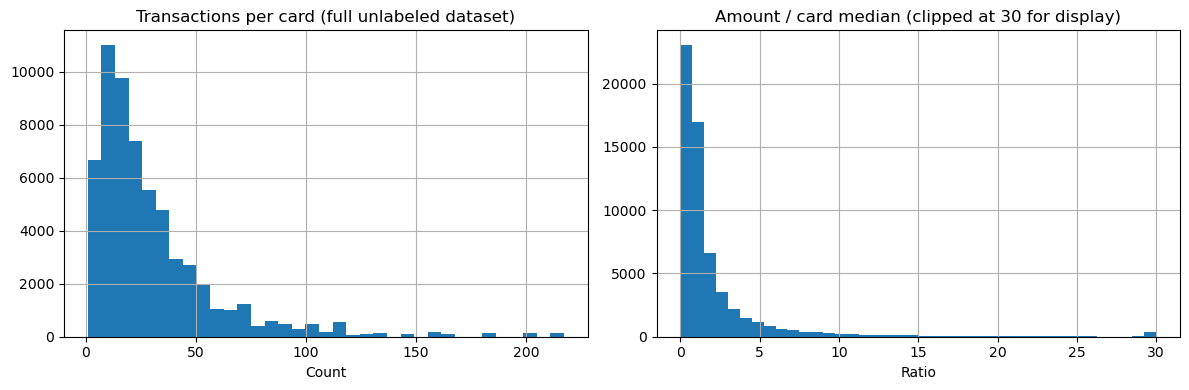

In [3]:
assert (train_features["card_transaction_count"] >= 1).all()
assert (train_features["card_amount_median"] > 0).all()
assert (train_features["card_amount_mean"] > 0).all()

summary_columns = ["amount"] + engineered_features
display(
    train_features[summary_columns]
    .describe(percentiles=[0.01, 0.10, 0.50, 0.90, 0.99])
    .T
)

# Diagnostic plots are for understanding only; do not choose features
# based solely on their relationship with fraud in the full training set.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_features["card_transaction_count"].hist(bins=35, ax=axes[0])
axes[0].set(title="Transactions per card (full unlabeled dataset)", xlabel="Count")

ratio_for_plot = train_features["amount_to_card_median"].clip(upper=30)
ratio_for_plot.hist(bins=40, ax=axes[1])
axes[1].set(title="Amount / card median (clipped at 30 for display)", xlabel="Ratio")
plt.tight_layout()
plt.show()

## 4 — Reuse E001 features and the exact same chronological folds

We avoid changing multiple elements of the experiment at once:

- Same 14 original features and categorical preprocessing as E001.
- Same **three** date cutoffs: Jan 19, Jan 25, and Jan 31, with six-day validation windows.
- Same CatBoost GPU parameters and early-stopping rule.
- Only the **feature set** changes between the experiments.

**Why not shuffled StratifiedKFold?** The competition's held-out labels are from later transactions, so we validate on later labels as well.

In [4]:
excluded = {
    "transaction_id", "timestamp", "card_holder", "merchant_name",
    "ip_address", "is_fraud",
}
original_features = [column for column in train_raw.columns if column not in excluded]
assert len(original_features) == 14, original_features

feature_sets = {
    "E001-repeat": original_features,
    "E002-A": original_features + ["card_amount_median", "card_amount_mean"],
    "E002-B": original_features + [
        "card_amount_median", "card_amount_mean",
        "amount_to_card_median", "amount_minus_card_median",
    ],
    "E002-C": original_features + engineered_features,
}

# All categorical types come from original data; new features are numerical.
cat_features = train_raw[original_features].select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# Use precisely the same time windows as E001-B.
time_folds = [
    ("2026-01-19", "2026-01-25"),
    ("2026-01-25", "2026-01-31"),
    ("2026-01-31", "2026-02-06"),
]

for name, columns in feature_sets.items():
    assert len(columns) == len(set(columns)), f"Duplicate columns in {name}"
    print(f"{name}: {len(columns)} features")

print("Categorical columns:", cat_features)

E001-repeat: 14 features
E002-A: 16 features
E002-B: 18 features
E002-C: 20 features
Categorical columns: ['card_id', 'customer_home_country', 'merchant_id', 'merchant_category', 'merchant_country', 'channel', 'device_id', 'ip_country']


## 5 — Inspect the folds before fitting

A fold is valid only when both training and validation contain **both classes**; ROC AUC cannot be computed from a one-class validation set.

The table also reveals whether the validation fraud rate shifts between periods. We do **not** stratify the dates to force equal fraud rates.

In [5]:
fold_info = []
for fold_number, (start, end) in enumerate(time_folds, start=1):
    start_date = pd.Timestamp(start)
    end_date = pd.Timestamp(end)
    training_mask = train_features["timestamp"] < start_date
    validation_mask = (
        train_features["timestamp"].ge(start_date)
        & train_features["timestamp"].lt(end_date)
    )
    train_y = train_features.loc[training_mask, "is_fraud"]
    valid_y = train_features.loc[validation_mask, "is_fraud"]
    assert train_y.nunique() == 2, f"Train fold {fold_number} has one class"
    assert valid_y.nunique() == 2, f"Validation fold {fold_number} has one class"
    assert train_features.loc[training_mask, "timestamp"].max() < start_date
    fold_info.append({
        "fold": fold_number,
        "valid_start": start,
        "valid_end_exclusive": end,
        "train_rows": len(train_y),
        "train_frauds": int(train_y.sum()),
        "valid_rows": len(valid_y),
        "valid_frauds": int(valid_y.sum()),
        "valid_fraud_rate": valid_y.mean(),
    })

display(pd.DataFrame(fold_info))

,fold,valid_start,valid_end_exclusive,train_rows,train_frauds,valid_rows,valid_frauds,valid_fraud_rate
0,1,2026-01-19,2026-01-25,29618,409,10336,140,0.013545
1,2,2026-01-25,2026-01-31,39954,549,10263,94,0.009159
2,3,2026-01-31,2026-02-06,50217,643,9980,156,0.015631


## 6 — Run the GPU experiments

`CatBoostClassifier.fit()` trains a fresh boosted-tree model for **each experiment and fold**.

- `loss_function="Logloss"`: the objective being minimized during training.
- `eval_metric="AUC"`: the score watched for early stopping.
- `task_type="GPU", devices="0"`: force NVIDIA GPU training; there is **no automatic CPU fallback**.
- `predict_proba(X_valid)[:, 1]`: predicted probability for class 1 (fraud).
- `roc_auc_score(...)`: evaluates how well fraud is ranked above legitimate transactions.

**Training volume:** Four feature sets × three folds = **12 GPU fits**. If you want a quick smoke test, set `EXPERIMENTS_TO_RUN = ["E001-repeat", "E002-A"]`, then restore all four for the complete experiment.

CatBoost GPU can be slightly nondeterministic. Comparing on the same folds and settings is nevertheless much fairer than comparing different datasets.

In [6]:
EXPERIMENTS_TO_RUN = ["E001-repeat", "E002-A", "E002-B", "E002-C"]

model_parameters = dict(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=3.0,
    loss_function="Logloss",
    eval_metric="AUC",
    task_type="GPU",      # NVIDIA GPU required
    devices="0",          # RTX 3070 (GPU 0)
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)

results = []
last_model = None
last_feature_columns = None

for experiment_name in EXPERIMENTS_TO_RUN:
    feature_columns = feature_sets[experiment_name]
    print(f"\n===== {experiment_name}: {len(feature_columns)} features =====")

    for fold_number, (start, end) in enumerate(time_folds, start=1):
        start_date, end_date = pd.Timestamp(start), pd.Timestamp(end)
        training_mask = train_features["timestamp"].lt(start_date)
        validation_mask = (
            train_features["timestamp"].ge(start_date)
            & train_features["timestamp"].lt(end_date)
        )

        X_train = train_features.loc[training_mask, feature_columns].copy()
        X_valid = train_features.loc[validation_mask, feature_columns].copy()
        y_train = train_features.loc[training_mask, "is_fraud"]
        y_valid = train_features.loc[validation_mask, "is_fraud"]

        # Match E001 categorical preprocessing, without changing numeric values.
        for frame in (X_train, X_valid):
            frame["card_present"] = frame["card_present"].astype("int8")
            frame[cat_features] = frame[cat_features].fillna("__MISSING__").astype(str)
        assert X_train.columns.tolist() == X_valid.columns.tolist()
        assert X_train[cat_features].isna().sum().sum() == 0
        assert X_train.select_dtypes(include=["number"]).notna().all().all()

        fold_model = CatBoostClassifier(**model_parameters)
        start_time = perf_counter()
        fold_model.fit(
            X_train, y_train,
            cat_features=cat_features,
            eval_set=(X_valid, y_valid),
            early_stopping_rounds=70,
            use_best_model=True,
        )
        duration_seconds = perf_counter() - start_time

        valid_probabilities = fold_model.predict_proba(X_valid)[:, 1]
        valid_auc = roc_auc_score(y_valid, valid_probabilities)

        results.append({
            "experiment_id": experiment_name,
            "fold": fold_number,
            "feature_count": len(feature_columns),
            "train_rows": len(y_train),
            "valid_rows": len(y_valid),
            "valid_frauds": int(y_valid.sum()),
            "roc_auc": valid_auc,
            "best_iteration": int(fold_model.best_iteration_),
            "training_seconds": round(duration_seconds, 2),
        })
        print(
            f"Fold {fold_number}: AUC={valid_auc:.4f} "
            f"| best_iteration={fold_model.best_iteration_} "
            f"| {duration_seconds:.1f}s"
        )
        if experiment_name == "E002-C" and fold_number == len(time_folds):
            last_model = fold_model
            last_feature_columns = feature_columns

results_df = pd.DataFrame(results)
display(results_df)


===== E001-repeat: 14 features =====


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 1: AUC=0.8868 | best_iteration=90 | 9.4s


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 2: AUC=0.8375 | best_iteration=16 | 5.1s


Default metric period is 5 because AUC is/are not implemented for GPU


... (16 outputs left out)

Fold 2: AUC=0.8870 | best_iteration=122 | 11.2s


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 3: AUC=0.8735 | best_iteration=12 | 2.9s


,experiment_id,fold,feature_count,train_rows,valid_rows,valid_frauds,roc_auc,best_iteration,training_seconds
0,E001-repeat,1,14,29618,10336,140,0.886804,90,9.42
1,E001-repeat,2,14,39954,10263,94,0.837461,16,5.12
2,E001-repeat,3,14,50217,9980,156,0.898440,14,2.76
3,E002-A,1,16,29618,10336,140,0.897720,596,34.11
4,E002-A,2,16,39954,10263,94,0.868198,597,34.02
5,E002-A,3,16,50217,9980,156,0.895906,14,2.78
6,E002-B,1,18,29618,10336,140,0.903054,76,8.48
7,E002-B,2,18,39954,10263,94,0.874207,15,5.29
8,E002-B,3,18,50217,9980,156,0.902567,11,2.65
9,E002-C,1,20,29618,10336,140,0.902144,69,8.10


## 7 — Compare E001 against E002-A/B/C

We look at **mean ROC AUC**, **fold-to-fold variability**, and **change from E001**. The mean is an unweighted average of the three fold AUCs, matching the E001-B reporting method.

\[
\Delta \mathrm{AUC} = \overline{\mathrm{AUC}}_{\mathrm{E002}} - \overline{\mathrm{AUC}}_{\mathrm{E001-repeat}}
\]

An improvement in the mean is promising, but **look at each fold**: a small difference may be noise, especially with few fraud examples. Because the validation labels are also used to choose the best iteration, these are **development scores**, not a completely independent final test estimate.

,experiment_id,mean_roc_auc,std_roc_auc,min_fold_auc,max_fold_auc,mean_best_iteration,delta_vs_e001
0,E001-repeat,0.87424,0.03237,0.83746,0.89844,40.00000,0.00000
1,E002-A,0.88727,0.01655,0.86820,0.89772,402.33333,0.01304
2,E002-B,0.89328,0.01652,0.87421,0.90305,34.00000,0.01904
3,E002-C,0.88756,0.01431,0.87354,0.90214,67.66667,0.01333


experiment_id,E001-repeat,E002-A,E002-B,E002-C
fold,,,,
1,0.88680,0.89772,0.90305,0.90214
2,0.83746,0.86820,0.87421,0.88700
3,0.89844,0.89591,0.90257,0.87354


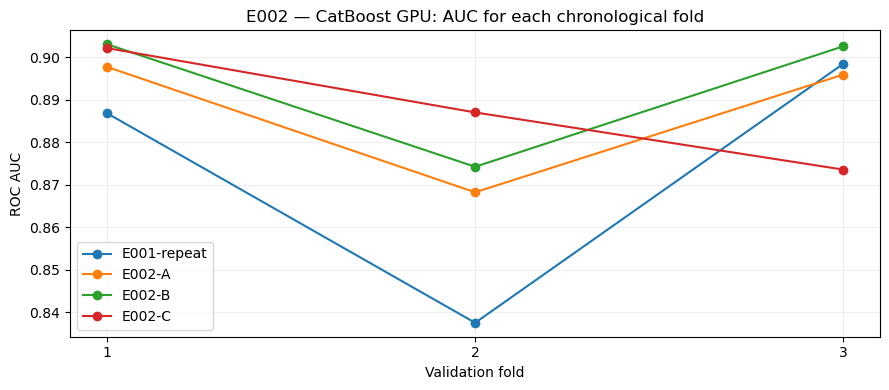

In [7]:
summary_df = (
    results_df.groupby("experiment_id", sort=False)
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        min_fold_auc=("roc_auc", "min"),
        max_fold_auc=("roc_auc", "max"),
        mean_best_iteration=("best_iteration", "mean"),
    )
    .reset_index()
)

baseline_rows = summary_df.loc[summary_df["experiment_id"] == "E001-repeat", "mean_roc_auc"]
if len(baseline_rows):
    baseline_auc = baseline_rows.iloc[0]
    summary_df["delta_vs_e001"] = summary_df["mean_roc_auc"] - baseline_auc
else:
    print("Baseline not rerun. Run E001-repeat for a controlled delta comparison.")

display(summary_df.round(5))

fold_auc_table = results_df.pivot(index="fold", columns="experiment_id", values="roc_auc")
display(fold_auc_table.round(5))

fig, ax = plt.subplots(figsize=(9, 4))
for experiment_name in fold_auc_table.columns:
    ax.plot(
        fold_auc_table.index,
        fold_auc_table[experiment_name],
        marker="o", label=experiment_name,
    )
ax.set(
    title="E002 — CatBoost GPU: AUC for each chronological fold",
    xlabel="Validation fold", ylabel="ROC AUC",
    xticks=[1, 2, 3],
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8 — Inspect feature importance (diagnostic only)

For the final E002-C fold, `get_feature_importance()` estimates which features influence the trained CatBoost model. This is **not** enough, by itself, to select or discard columns. We rely primarily on repeated validation performance.

In [8]:
if last_model is not None:
    importance_df = (
        pd.DataFrame({
            "feature": last_feature_columns,
            "importance": last_model.get_feature_importance(),
        })
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )
    display(importance_df.head(20))
else:
    print("Run E002-C to view its final fold feature importance.")

,feature,importance
0,amount_to_card_median,41.546808
1,merchant_id,19.389985
2,merchant_category,11.154355
3,is_foreign_merchant,6.037736
4,channel,4.596163
5,merchant_country,2.874647
6,is_foreign_ip,2.252225
7,customer_home_country,2.087132
8,amount_minus_card_median,2.080126
9,card_amount_mean,1.762536


## 9 — Export reproducible experiment results

Save just the **summary metrics**, not the large fitted models or CatBoost logs. Our `.gitignore` can continue excluding `models/` and `catboost_info/`, while the small experiment CSVs can be committed to GitHub.

The notebook writes separate E002 result files; it **does not overwrite** your existing `experiments/results.csv` baseline log.

In [9]:
experiments_dir = project_root / "experiments"
experiments_dir.mkdir(parents=True, exist_ok=True)

fold_result_path = experiments_dir / "E002_cv_results.csv"
summary_result_path = experiments_dir / "E002_summary.csv"
results_df.to_csv(fold_result_path, index=False)
summary_df.to_csv(summary_result_path, index=False)

print("Saved fold results:", fold_result_path)
print("Saved summary:", summary_result_path)

Saved fold results: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E002_cv_results.csv
Saved summary: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E002_summary.csv


## 10 — Interpretation (fill in after running)

| Question | What to record |
|:--|:--|
| Did E002-A improve mean AUC versus E001-repeat? | Difference in mean and each fold |
| Did amount ratio and difference improve E002-B? | Differences versus E002-A |
| Did variability/count improve E002-C? | Differences versus E002-B |
| Are improvements consistent across all folds? | Note where they increase/decrease |
| Are the best iterations unusually early? | Consider training/validation performance and distribution shift |

**Decision rule for the next experiment:** Retain promising spending feature sets as **candidates**, not as final selections. E003 (transaction velocity) will be tested **independently against the same original-feature baseline**; E006 will test combinations.

### Checkpoint

Why might `amount_to_card_median` convey more information about suspicious spending than `amount` alone, and why does that not guarantee it will improve ROC AUC?